# IncidentIQ: Production Incident Investigation & IT Service Management Analytics

### Domain
IT Service Management (ITSM)

### Technologies
Python • Pandas • NumPy • Matplotlib • Seaborn • Plotly • SQL • Jupyter Notebook

### Project Overview
This project analyzes real-world IT incident management data to identify operational bottlenecks, monitor service performance, evaluate SLA compliance, investigate incident trends, and generate actionable insights for improving technical support operations.

The analysis follows a complete data analytics workflow including data cleaning, feature engineering, exploratory data analysis (EDA), business insights, and operational recommendations.

# 1. Business Problem

Organizations receive thousands of IT support incidents every day. Without analyzing historical incident data, it becomes difficult to answer important operational questions such as:

- Which incident categories occur most frequently?
- Which support teams receive the highest workload?
- Are Service Level Agreements (SLAs) consistently achieved?
- Which incidents require repeated reassignment?
- Which priorities consume the most support effort?
- How long does incident resolution typically take?

This project analyzes historical incident data to identify operational inefficiencies and provide data-driven recommendations for improving IT support performance.

### 2. Project Objectives

The primary objectives of this project are:

- Analyze historical IT incident data.
- Understand ticket distribution across categories and priorities.
- Evaluate SLA compliance.
- Investigate incident reassignment patterns.
- Analyze incident resolution timelines.
- Identify operational bottlenecks.
- Generate business recommendations for improving technical support efficiency.

### 3. Dataset Description

### Dataset Information

**Dataset Name:** Incident Event Log

**Source:** Kaggle

**Domain:** IT Service Management (ITSM)

### Dataset Summary

- Total Records: 141,712
- Total Features: 36
- Incident-based historical support records
- Multiple categorical, numerical, boolean, and datetime attributes

The dataset contains information related to incident lifecycle, priorities, support teams, SLA performance, resolution details, and assignment history.

### 4. Business Questions

This analysis aims to answer the following business questions:

1. Which incident states occur most frequently?

2. Which categories generate the highest number of incidents?

3. Which priorities dominate support operations?

4. Which assignment groups handle the largest workload?

5. Are Service Level Agreements (SLAs) consistently achieved?

6. Which contact channels generate the most incidents?

7. What is the average incident resolution time?

8. Which incident categories experience the longest resolution times?

9. Which locations generate the highest support demand?

10. Which support groups experience repeated incident reassignments?

11. What operational improvements can reduce support workload and improve customer satisfaction?

### 5. Import Required Libraries

In [1]:
import numpy as np
import pandas as pd

In [2]:
 import matplotlib.pyplot as plt

# Display all columns
pd.set_option('display.max_columns', None)

# Display wider tables
pd.set_option('display.width', None)

###  6. Load Dataset

The dataset is loaded into a Pandas DataFrame to begin the data analysis process.

In [3]:
df = pd.read_csv('incident_event_log.csv')
df.head(5)

,number,incident_state,active,reassignment_count,reopen_count,sys_mod_count,made_sla,caller_id,opened_by,opened_at,sys_created_by,sys_created_at,sys_updated_by,sys_updated_at,contact_type,location,category,subcategory,u_symptom,cmdb_ci,impact,urgency,priority,assignment_group,assigned_to,knowledge,u_priority_confirmation,notify,problem_id,rfc,vendor,caused_by,closed_code,resolved_by,resolved_at,closed_at
0,INC0000045,New,True,0,0,0,True,Caller 2403,Opened by 8,29/2/2016 01:16,Created by 6,29/2/2016 01:23,Updated by 21,29/2/2016 01:23,Phone,Location 143,Category 55,Subcategory 170,Symptom 72,?,2 - Medium,2 - Medium,3 - Moderate,Group 56,?,True,False,Do Not Notify,?,?,?,?,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
1,INC0000045,Resolved,True,0,0,2,True,Caller 2403,Opened by 8,29/2/2016 01:16,Created by 6,29/2/2016 01:23,Updated by 642,29/2/2016 08:53,Phone,Location 143,Category 55,Subcategory 170,Symptom 72,?,2 - Medium,2 - Medium,3 - Moderate,Group 56,?,True,False,Do Not Notify,?,?,?,?,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
2,INC0000045,Resolved,True,0,0,3,True,Caller 2403,Opened by 8,29/2/2016 01:16,Created by 6,29/2/2016 01:23,Updated by 804,29/2/2016 11:29,Phone,Location 143,Category 55,Subcategory 170,Symptom 72,?,2 - Medium,2 - Medium,3 - Moderate,Group 56,?,True,False,Do Not Notify,?,?,?,?,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
3,INC0000045,Closed,False,0,0,4,True,Caller 2403,Opened by 8,29/2/2016 01:16,Created by 6,29/2/2016 01:23,Updated by 908,5/3/2016 12:00,Phone,Location 143,Category 55,Subcategory 170,Symptom 72,?,2 - Medium,2 - Medium,3 - Moderate,Group 56,?,True,False,Do Not Notify,?,?,?,?,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
4,INC0000047,New,True,0,0,0,True,Caller 2403,Opened by 397,29/2/2016 04:40,Created by 171,29/2/2016 04:57,Updated by 746,29/2/2016 04:57,Phone,Location 165,Category 40,Subcategory 215,Symptom 471,?,2 - Medium,2 - Medium,3 - Moderate,Group 70,Resolver 89,True,False,Do Not Notify,?,?,?,?,code 5,Resolved by 81,1/3/2016 09:52,6/3/2016 10:00


### 7. Initial Dataset Exploration

In [4]:
df.shape

(141712, 36)

In [5]:
df.dtypes

number                     object
incident_state             object
active                       bool
reassignment_count          int64
reopen_count                int64
sys_mod_count               int64
made_sla                     bool
caller_id                  object
opened_by                  object
opened_at                  object
sys_created_by             object
sys_created_at             object
sys_updated_by             object
sys_updated_at             object
contact_type               object
location                   object
category                   object
subcategory                object
u_symptom                  object
cmdb_ci                    object
impact                     object
urgency                    object
priority                   object
assignment_group           object
assigned_to                object
knowledge                    bool
u_priority_confirmation      bool
notify                     object
problem_id                 object
rfc           

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 141712 entries, 0 to 141711
Data columns (total 36 columns):
 #   Column                   Non-Null Count   Dtype 
---  ------                   --------------   ----- 
 0   number                   141712 non-null  object
 1   incident_state           141712 non-null  object
 2   active                   141712 non-null  bool  
 3   reassignment_count       141712 non-null  int64 
 4   reopen_count             141712 non-null  int64 
 5   sys_mod_count            141712 non-null  int64 
 6   made_sla                 141712 non-null  bool  
 7   caller_id                141712 non-null  object
 8   opened_by                141712 non-null  object
 9   opened_at                141712 non-null  object
 10  sys_created_by           141712 non-null  object
 11  sys_created_at           141712 non-null  object
 12  sys_updated_by           141712 non-null  object
 13  sys_updated_at           141712 non-null  object
 14  contact_type        

In [7]:
df.isnull().sum().sort_values(ascending=False)

number                     0
incident_state             0
impact                     0
urgency                    0
priority                   0
assignment_group           0
assigned_to                0
knowledge                  0
u_priority_confirmation    0
notify                     0
problem_id                 0
rfc                        0
vendor                     0
caused_by                  0
closed_code                0
resolved_by                0
resolved_at                0
cmdb_ci                    0
u_symptom                  0
subcategory                0
opened_by                  0
active                     0
reassignment_count         0
reopen_count               0
sys_mod_count              0
made_sla                   0
caller_id                  0
opened_at                  0
category                   0
sys_created_by             0
sys_created_at             0
sys_updated_by             0
sys_updated_at             0
contact_type               0
location      

In [8]:
df.columns

Index(['number', 'incident_state', 'active', 'reassignment_count',
       'reopen_count', 'sys_mod_count', 'made_sla', 'caller_id', 'opened_by',
       'opened_at', 'sys_created_by', 'sys_created_at', 'sys_updated_by',
       'sys_updated_at', 'contact_type', 'location', 'category', 'subcategory',
       'u_symptom', 'cmdb_ci', 'impact', 'urgency', 'priority',
       'assignment_group', 'assigned_to', 'knowledge',
       'u_priority_confirmation', 'notify', 'problem_id', 'rfc', 'vendor',
       'caused_by', 'closed_code', 'resolved_by', 'resolved_at', 'closed_at'],
      dtype='object')

In [9]:
for column in df.columns:
    print(column)

number
incident_state
active
reassignment_count
reopen_count
sys_mod_count
made_sla
caller_id
opened_by
opened_at
sys_created_by
sys_created_at
sys_updated_by
sys_updated_at
contact_type
location
category
subcategory
u_symptom
cmdb_ci
impact
urgency
priority
assignment_group
assigned_to
knowledge
u_priority_confirmation
notify
problem_id
rfc
vendor
caused_by
closed_code
resolved_by
resolved_at
closed_at


In [10]:
df.describe(include='all')

,number,incident_state,active,reassignment_count,reopen_count,sys_mod_count,made_sla,caller_id,opened_by,opened_at,sys_created_by,sys_created_at,sys_updated_by,sys_updated_at,contact_type,location,category,subcategory,u_symptom,cmdb_ci,impact,urgency,priority,assignment_group,assigned_to,knowledge,u_priority_confirmation,notify,problem_id,rfc,vendor,caused_by,closed_code,resolved_by,resolved_at,closed_at
count,141712,141712,141712,141712.000000,141712.000000,141712.000000,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712
unique,24918,9,2,NaN,NaN,NaN,2,5245,208,19849,186,11553,846,50664,5,225,59,255,526,51,3,3,4,79,235,2,2,2,253,182,5,4,18,217,18506,2707
top,INC0019396,Active,True,NaN,NaN,NaN,True,Caller 1904,Opened by 17,14/4/2016 20:42,?,?,Updated by 908,24/3/2016 18:40,Phone,Location 204,Category 26,Subcategory 174,Symptom 491,?,2 - Medium,2 - Medium,3 - Moderate,Group 70,?,False,False,Do Not Notify,?,?,?,?,code 6,Resolved by 15,?,24/3/2016 18:59
freq,58,38716,116726,NaN,NaN,NaN,132497,1425,41466,58,53076,53076,36162,420,140462,31690,18453,35785,51985,141267,134335,134094,132452,43474,27496,116349,100740,141593,139417,140721,141468,141689,86583,15421,3141,3324
mean,NaN,NaN,NaN,1.104197,0.021918,5.080946,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,1.734673,0.207302,7.680652,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,0.000000,0.000000,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,1.000000,0.000000,3.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,1.000000,0.000000,6.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
duplicates = df.duplicated().sum()

print("Duplicate Rows :", duplicates)

Duplicate Rows : 0


In [12]:
df['number'].nunique()

24918

In [13]:
print("Total Rows :", len(df))
print("Unique Incidents :", df['number'].nunique())

Total Rows : 141712
Unique Incidents : 24918


In [14]:
df['incident_state'].value_counts()

Active                38716
New                   36407
Resolved              25751
Closed                24985
Awaiting User Info    14642
Awaiting Vendor         707
Awaiting Problem        461
Awaiting Evidence        38
-100                      5
Name: incident_state, dtype: int64

In [15]:
df['category'].value_counts()

Category 26    18453
Category 42    15977
Category 53    15968
Category 46    13324
Category 23     7779
Category 9      7365
Category 32     7273
Category 37     6584
Category 57     6532
Category 20     5506
Category 61     5168
Category 24     4561
Category 34     3946
Category 40     3760
Category 45     3619
Category 51     2390
Category 28     2256
Category 35     2037
Category 44     1798
Category 19     1592
Category 13      994
Category 43      858
Category 55      801
Category 17      512
Category 22      420
Category 56      322
Category 38      290
Category 8       264
Category 7       207
Category 33      160
Category 54      139
Category 50       93
Category 31       92
Category 63       78
?                 78
Category 2        77
Category 21       69
Category 47       50
Category 59       42
Category 41       36
Category 29       32
Category 5        31
Category 25       30
Category 62       25
Category 10       24
Category 4        22
Category 52       16
Category 30  

### 8. Data Cleaning

Data cleaning is performed to improve data quality and ensure accurate analysis.

The following preprocessing steps are carried out:

- Convert date columns into datetime format.
- Handle missing values.
- Remove duplicate records (if present).
- Standardize column names.
- Verify data types.
- Validate overall dataset consistency.

In [16]:
incident_df = df.copy()

In [17]:
missing = pd.DataFrame({
    "Missing Values": incident_df.isnull().sum(),
    "Percentage": round((incident_df.isnull().sum()/len(incident_df))*100,2)
})

missing.sort_values("Percentage", ascending=False)

,Missing Values,Percentage
number,0,0.0
incident_state,0,0.0
impact,0,0.0
urgency,0,0.0
priority,0,0.0
assignment_group,0,0.0
assigned_to,0,0.0
knowledge,0,0.0
u_priority_confirmation,0,0.0
notify,0,0.0


In [18]:
incident_df['number'].value_counts().head(20)

INC0019396    58
INC0044260    56
INC0005927    46
INC0020718    45
INC0011206    44
INC0025734    43
INC0007349    43
INC0012815    40
INC0003419    38
INC0032450    38
INC0020849    38
INC0015902    37
INC0002129    36
INC0019739    35
INC0010322    34
INC0003256    33
INC0007229    33
INC0026226    33
INC0004305    33
INC0025696    33
Name: number, dtype: int64

In [19]:
date_columns = [
    'opened_at',
    'sys_created_at',
    'sys_updated_at',
    'resolved_at',
    'closed_at'
]

incident_df[date_columns].head()

,opened_at,sys_created_at,sys_updated_at,resolved_at,closed_at
0,29/2/2016 01:16,29/2/2016 01:23,29/2/2016 01:23,29/2/2016 11:29,5/3/2016 12:00
1,29/2/2016 01:16,29/2/2016 01:23,29/2/2016 08:53,29/2/2016 11:29,5/3/2016 12:00
2,29/2/2016 01:16,29/2/2016 01:23,29/2/2016 11:29,29/2/2016 11:29,5/3/2016 12:00
3,29/2/2016 01:16,29/2/2016 01:23,5/3/2016 12:00,29/2/2016 11:29,5/3/2016 12:00
4,29/2/2016 04:40,29/2/2016 04:57,29/2/2016 04:57,1/3/2016 09:52,6/3/2016 10:00


In [20]:
for col in date_columns:
    incident_df[col] = pd.to_datetime(
        incident_df[col],
        errors='coerce'
    )

In [21]:
incident_df[date_columns].dtypes

opened_at         datetime64[ns]
sys_created_at    datetime64[ns]
sys_updated_at    datetime64[ns]
resolved_at       datetime64[ns]
closed_at         datetime64[ns]
dtype: object

In [22]:
incident_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 141712 entries, 0 to 141711
Data columns (total 36 columns):
 #   Column                   Non-Null Count   Dtype         
---  ------                   --------------   -----         
 0   number                   141712 non-null  object        
 1   incident_state           141712 non-null  object        
 2   active                   141712 non-null  bool          
 3   reassignment_count       141712 non-null  int64         
 4   reopen_count             141712 non-null  int64         
 5   sys_mod_count            141712 non-null  int64         
 6   made_sla                 141712 non-null  bool          
 7   caller_id                141712 non-null  object        
 8   opened_by                141712 non-null  object        
 9   opened_at                141712 non-null  datetime64[ns]
 10  sys_created_by           141712 non-null  object        
 11  sys_created_at           88636 non-null   datetime64[ns]
 12  sys_updated_by  

Step 21 — Create a Data Quality Report

In [23]:
# Missing Values Report
missing_df = pd.DataFrame({
    'Missing Values': incident_df.isnull().sum(),
    'Percentage (%)': round((incident_df.isnull().sum()/len(incident_df))*100,2)
})

missing_df = missing_df[missing_df['Missing Values'] > 0]

missing_df.sort_values('Percentage (%)', ascending=False)

,Missing Values,Percentage (%)
sys_created_at,53076,37.45
resolved_at,3141,2.22


Step 22 — Check Duplicate Rows

In [24]:
print("Duplicate Rows :", incident_df.duplicated().sum())

Duplicate Rows : 0


Step 23 — Check Duplicate Incident IDs

In [25]:
print("Unique Incidents :", incident_df['number'].nunique())

print("Total Records :", len(incident_df))

Unique Incidents : 24918
Total Records : 141712


Step 24 — Understand the Dataset

In [26]:
incident_df.describe(include='all')

<ipython-input-26-686628f8dbea>:1: FutureWarning: Treating datetime data as categorical rather than numeric in `.describe` is deprecated and will be removed in a future version of pandas. Specify `datetime_is_numeric=True` to silence this warning and adopt the future behavior now.
  incident_df.describe(include='all')
<ipython-input-26-686628f8dbea>:1: FutureWarning: Treating datetime data as categorical rather than numeric in `.describe` is deprecated and will be removed in a future version of pandas. Specify `datetime_is_numeric=True` to silence this warning and adopt the future behavior now.
  incident_df.describe(include='all')
<ipython-input-26-686628f8dbea>:1: FutureWarning: Treating datetime data as categorical rather than numeric in `.describe` is deprecated and will be removed in a future version of pandas. Specify `datetime_is_numeric=True` to silence this warning and adopt the future behavior now.
  incident_df.describe(include='all')
<ipython-input-26-686628f8dbea>:1: Futur

,number,incident_state,active,reassignment_count,reopen_count,sys_mod_count,made_sla,caller_id,opened_by,opened_at,sys_created_by,sys_created_at,sys_updated_by,sys_updated_at,contact_type,location,category,subcategory,u_symptom,cmdb_ci,impact,urgency,priority,assignment_group,assigned_to,knowledge,u_priority_confirmation,notify,problem_id,rfc,vendor,caused_by,closed_code,resolved_by,resolved_at,closed_at
count,141712,141712,141712,141712.000000,141712.000000,141712.000000,141712,141712,141712,141712,141712,88636,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712,141712,138571,141712
unique,24918,9,2,NaN,NaN,NaN,2,5245,208,19849,186,11552,846,50664,5,225,59,255,526,51,3,3,4,79,235,2,2,2,253,182,5,4,18,217,18505,2707
top,INC0019396,Active,True,NaN,NaN,NaN,True,Caller 1904,Opened by 17,2016-04-14 20:42:00,?,2016-04-07 14:50:00,Updated by 908,2016-03-24 18:40:00,Phone,Location 204,Category 26,Subcategory 174,Symptom 491,?,2 - Medium,2 - Medium,3 - Moderate,Group 70,?,False,False,Do Not Notify,?,?,?,?,code 6,Resolved by 15,2016-03-06 16:29:00,2016-03-24 18:59:00
freq,58,38716,116726,NaN,NaN,NaN,132497,1425,41466,58,53076,56,36162,420,140462,31690,18453,35785,51985,141267,134335,134094,132452,43474,27496,116349,100740,141593,139417,140721,141468,141689,86583,15421,93,3324
first,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2016-01-03 01:22:00,NaN,2016-01-03 01:35:00,NaN,2016-01-03 00:01:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2016-01-03 02:55:00,2016-01-04 00:59:00
last,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017-12-01 18:17:00,NaN,2017-12-01 18:18:00,NaN,2017-12-02 17:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017-12-01 18:18:00,2017-12-02 17:00:00
mean,NaN,NaN,NaN,1.104197,0.021918,5.080946,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,1.734673,0.207302,7.680652,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,0.000000,0.000000,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [27]:
incident_df.head()

,number,incident_state,active,reassignment_count,reopen_count,sys_mod_count,made_sla,caller_id,opened_by,opened_at,sys_created_by,sys_created_at,sys_updated_by,sys_updated_at,contact_type,location,category,subcategory,u_symptom,cmdb_ci,impact,urgency,priority,assignment_group,assigned_to,knowledge,u_priority_confirmation,notify,problem_id,rfc,vendor,caused_by,closed_code,resolved_by,resolved_at,closed_at
0,INC0000045,New,True,0,0,0,True,Caller 2403,Opened by 8,2016-02-29 01:16:00,Created by 6,2016-02-29 01:23:00,Updated by 21,2016-02-29 01:23:00,Phone,Location 143,Category 55,Subcategory 170,Symptom 72,?,2 - Medium,2 - Medium,3 - Moderate,Group 56,?,True,False,Do Not Notify,?,?,?,?,code 5,Resolved by 149,2016-02-29 11:29:00,2016-05-03 12:00:00
1,INC0000045,Resolved,True,0,0,2,True,Caller 2403,Opened by 8,2016-02-29 01:16:00,Created by 6,2016-02-29 01:23:00,Updated by 642,2016-02-29 08:53:00,Phone,Location 143,Category 55,Subcategory 170,Symptom 72,?,2 - Medium,2 - Medium,3 - Moderate,Group 56,?,True,False,Do Not Notify,?,?,?,?,code 5,Resolved by 149,2016-02-29 11:29:00,2016-05-03 12:00:00
2,INC0000045,Resolved,True,0,0,3,True,Caller 2403,Opened by 8,2016-02-29 01:16:00,Created by 6,2016-02-29 01:23:00,Updated by 804,2016-02-29 11:29:00,Phone,Location 143,Category 55,Subcategory 170,Symptom 72,?,2 - Medium,2 - Medium,3 - Moderate,Group 56,?,True,False,Do Not Notify,?,?,?,?,code 5,Resolved by 149,2016-02-29 11:29:00,2016-05-03 12:00:00
3,INC0000045,Closed,False,0,0,4,True,Caller 2403,Opened by 8,2016-02-29 01:16:00,Created by 6,2016-02-29 01:23:00,Updated by 908,2016-05-03 12:00:00,Phone,Location 143,Category 55,Subcategory 170,Symptom 72,?,2 - Medium,2 - Medium,3 - Moderate,Group 56,?,True,False,Do Not Notify,?,?,?,?,code 5,Resolved by 149,2016-02-29 11:29:00,2016-05-03 12:00:00
4,INC0000047,New,True,0,0,0,True,Caller 2403,Opened by 397,2016-02-29 04:40:00,Created by 171,2016-02-29 04:57:00,Updated by 746,2016-02-29 04:57:00,Phone,Location 165,Category 40,Subcategory 215,Symptom 471,?,2 - Medium,2 - Medium,3 - Moderate,Group 70,Resolver 89,True,False,Do Not Notify,?,?,?,?,code 5,Resolved by 81,2016-01-03 09:52:00,2016-06-03 10:00:00


The purpose of this initial exploration is to understand the structure, quality, and completeness of the dataset before performing data cleaning.

Step 25 — Inspect Categorical Columns

In [28]:
categorical_columns = [
    'incident_state',
    'priority',
    'category',
    'subcategory',
    'impact',
    'urgency',
    'assignment_group',
    'contact_type'
]

for col in categorical_columns:
    print("="*60)
    print(col)
    print(incident_df[col].value_counts())

incident_state
Active                38716
New                   36407
Resolved              25751
Closed                24985
Awaiting User Info    14642
Awaiting Vendor         707
Awaiting Problem        461
Awaiting Evidence        38
-100                      5
Name: incident_state, dtype: int64
priority
3 - Moderate    132452
4 - Low           4030
2 - High          2972
1 - Critical      2258
Name: priority, dtype: int64
category
Category 26    18453
Category 42    15977
Category 53    15968
Category 46    13324
Category 23     7779
Category 9      7365
Category 32     7273
Category 37     6584
Category 57     6532
Category 20     5506
Category 61     5168
Category 24     4561
Category 34     3946
Category 40     3760
Category 45     3619
Category 51     2390
Category 28     2256
Category 35     2037
Category 44     1798
Category 19     1592
Category 13      994
Category 43      858
Category 55      801
Category 17      512
Category 22      420
Category 56      322
Category 38  

## 4. Business Questions

This project aims to answer the following operational questions:

1. Which incident priorities occur most frequently?
2. Which assignment groups receive the highest number of incidents?
3. Which incident categories generate the largest workload?
4. What percentage of incidents meet the Service Level Agreement (SLA)?
5. Which incidents require the highest number of reassignments?
6. What is the average incident resolution time?
7. Which contact channels generate the most incidents?
8. Which support teams handle the highest workload?
9. Which incident types are most likely to be reopened?
10. What operational improvements can reduce incident resolution time?

### 📍 Phase 3 — Exploratory Data Analysis (Business-Oriented)


In this section, we explore the incident management dataset to identify operational patterns, evaluate service performance, analyze incident characteristics, and generate actionable insights that support decision-making and continuous process improvement.

The objective of Exploratory Data Analysis is to identify hidden patterns, operational trends, workload distribution, and relationships among incident management variables.

EDA 1 — Dataset Overview

### Business Question

What is the overall size and composition of the incident management dataset?

Understanding the dataset's size, number of unique incidents, and operational status provides a high-level overview before performing detailed analysis.

In [29]:
print("=" * 60)
print("IncidentIQ Dataset Overview")
print("=" * 60)

print(f"Total Records            : {len(incident_df):,}")
print(f"Total Features           : {incident_df.shape[1]}")
print(f"Unique Incidents         : {incident_df['number'].nunique():,}")
print(f"Active Incidents         : {incident_df['active'].sum():,}")
print(f"Closed/Inactive Incidents: {(~incident_df['active']).sum():,}")

IncidentIQ Dataset Overview
Total Records            : 141,712
Total Features           : 36
Unique Incidents         : 24,918
Active Incidents         : 116,726
Closed/Inactive Incidents: 24,986


Visualization

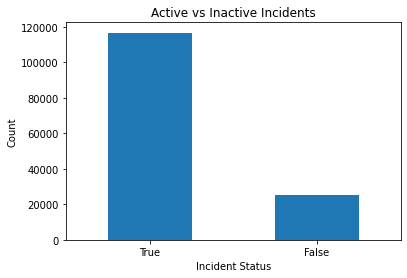

In [30]:
incident_df['active'].value_counts().plot(
    kind='bar',
    figsize=(6,4)
)

plt.title("Active vs Inactive Incidents")
plt.xlabel("Incident Status")
plt.ylabel("Count")

plt.xticks(rotation=0)

plt.show()

### Insights

- The majority of incidents are marked as **inactive**, indicating that most tickets in the dataset have already been resolved or closed.
- A comparatively smaller number of **active** incidents suggests that only a limited portion of the incident workload remained open at the time the data was captured.
- This distribution reflects a mature incident lifecycle where support teams successfully close most reported issues.
- The active incidents represent the current operational workload and may require further analysis to identify high-priority or aging tickets that need immediate attention.

## EDA 2: Incident Priority Analysis

### Business Question

Which incident priorities occur most frequently?

Understanding the distribution of incident priorities helps assess workload distribution and identify the proportion of critical incidents requiring immediate attention.

Which categories generate the highest number of incidents?

In [31]:
priority = incident_df['priority'].value_counts()

priority

3 - Moderate    132452
4 - Low           4030
2 - High          2972
1 - Critical      2258
Name: priority, dtype: int64

Visualization

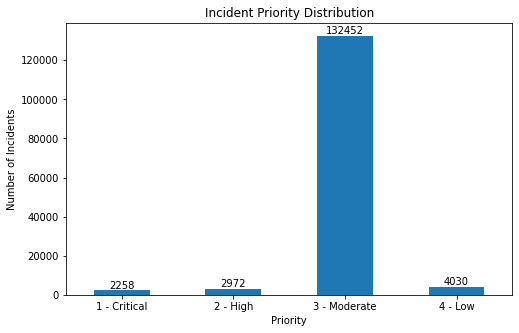

In [32]:
priority = incident_df['priority'].value_counts().sort_index()

ax = priority.plot(kind='bar', figsize=(8,5))

plt.title("Incident Priority Distribution")
plt.xlabel("Priority")
plt.ylabel("Number of Incidents")
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container)

plt.show()

### Insight

- The majority of incidents are classified as **Priority 3**, indicating that most support requests are of medium business impact and form the largest portion of the operational workload.
- **Priority 1, Priority 2, and Priority 4** incidents occur significantly less frequently, suggesting that critical and high-impact service disruptions are relatively uncommon.
- This distribution indicates that the support team spends most of its effort resolving routine operational incidents while remaining prepared to respond quickly to high-priority issues when they occur.
- Understanding the priority distribution helps management allocate support resources effectively, optimize workload planning, and monitor SLA compliance across different incident severities.

Percentage Distribution

In [33]:
round(
    incident_df['priority'].value_counts(normalize=True) * 100,
    2
)

3 - Moderate    93.47
4 - Low          2.84
2 - High         2.10
1 - Critical     1.59
Name: priority, dtype: float64

EDA 3 — Incident Category Analysis

## EDA 3: Incident Category Analysis

### Business Question

Which incident categories generate the highest number of support requests?

Analyzing incident categories helps identify the most common operational issues affecting IT services and supports resource planning.

In [34]:
category = incident_df['category'].value_counts()

category

Category 26    18453
Category 42    15977
Category 53    15968
Category 46    13324
Category 23     7779
Category 9      7365
Category 32     7273
Category 37     6584
Category 57     6532
Category 20     5506
Category 61     5168
Category 24     4561
Category 34     3946
Category 40     3760
Category 45     3619
Category 51     2390
Category 28     2256
Category 35     2037
Category 44     1798
Category 19     1592
Category 13      994
Category 43      858
Category 55      801
Category 17      512
Category 22      420
Category 56      322
Category 38      290
Category 8       264
Category 7       207
Category 33      160
Category 54      139
Category 50       93
Category 31       92
Category 63       78
?                 78
Category 2        77
Category 21       69
Category 47       50
Category 59       42
Category 41       36
Category 29       32
Category 5        31
Category 25       30
Category 62       25
Category 10       24
Category 4        22
Category 52       16
Category 30  

Visualization

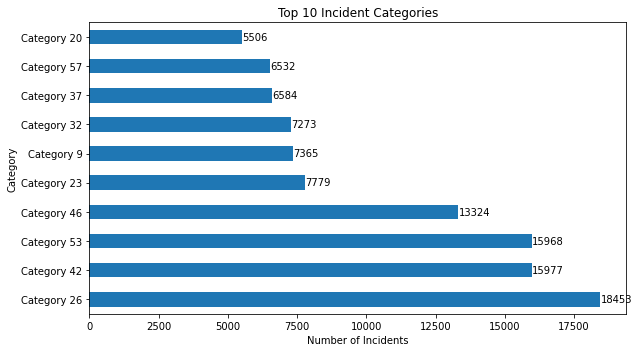

In [35]:
category = incident_df['category'].value_counts().head(10)

ax = category.plot(
    kind='barh',
    figsize=(9,5)
)

plt.title("Top 10 Incident Categories")
plt.xlabel("Number of Incidents")
plt.ylabel("Category")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

### Insight

- The incident workload is concentrated in a few major categories, indicating that certain types of technical issues occur much more frequently than others.
- The highest-volume categories represent the primary operational challenges faced by the IT support team and should be prioritized for proactive monitoring and process improvements.
- Categories with fewer incidents require comparatively fewer support resources but should continue to be monitored to detect any unexpected increase in occurrence.
- Understanding the distribution of incident categories helps support managers allocate resources effectively, prioritize training, and identify opportunities to reduce recurring incidents through preventive actions.

EDA 4 — Subcategory Analysis

### EDA 4: Incident Subcategory Analysis

### Business Question

Which incident subcategories contribute the highest volume of support requests?

This analysis provides a more detailed understanding of the specific issues driving incident volumes.

In [36]:
subcategory = incident_df['subcategory'].value_counts()

subcategory.head(15)

Subcategory 174    35785
Subcategory 223    15598
Subcategory 175    10496
Subcategory 164     7880
Subcategory 9       4124
Subcategory 275     3643
Subcategory 135     3467
Subcategory 170     3349
Subcategory 36      2917
Subcategory 75      2113
Subcategory 125     1947
Subcategory 3       1788
Subcategory 43      1674
Subcategory 150     1659
Subcategory 28      1565
Name: subcategory, dtype: int64

Visualization

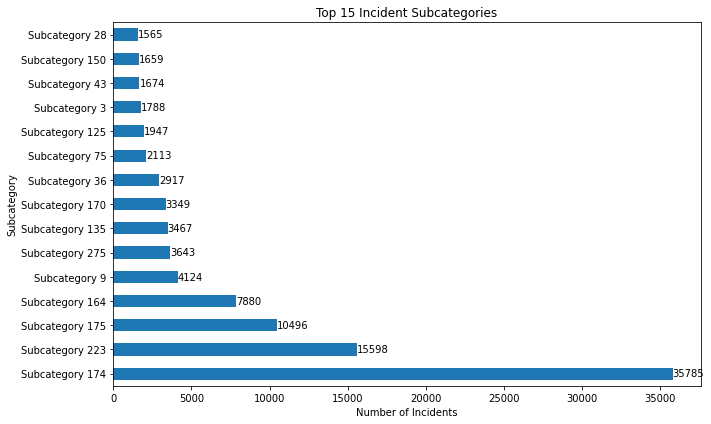

In [37]:
subcategory = incident_df['subcategory'].value_counts().head(15)

ax = subcategory.plot(
    kind='barh',
    figsize=(10,6)
)

plt.title("Top 15 Incident Subcategories")
plt.xlabel("Number of Incidents")
plt.ylabel("Subcategory")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

### Insight

- A small number of subcategories account for a significant proportion of all reported incidents, indicating that specific issue types occur repeatedly across the organization.
- The most frequent subcategory should be prioritized for root cause analysis, as reducing its occurrence could substantially decrease the overall incident volume.
- Lower-frequency subcategories represent specialized or less common issues that may require targeted expertise but have a smaller impact on the overall support workload.
- Analyzing incident subcategories enables IT teams to identify recurring problem areas, improve knowledge base articles, automate repetitive tasks, and implement preventive measures to reduce future incidents.

### EDA 5: Distribution of Incident States

This analysis examines the distribution of incidents across different lifecycle states (e.g., New, Active, Resolved, Closed). Understanding the frequency of each state helps identify workload distribution, ticket processing stages, and potential operational bottlenecks.

In [38]:
# Count incidents by state
state_counts = incident_df['incident_state'].value_counts().sort_values(ascending=False)

state_counts

Active                38716
New                   36407
Resolved              25751
Closed                24985
Awaiting User Info    14642
Awaiting Vendor         707
Awaiting Problem        461
Awaiting Evidence        38
-100                      5
Name: incident_state, dtype: int64

Visualization

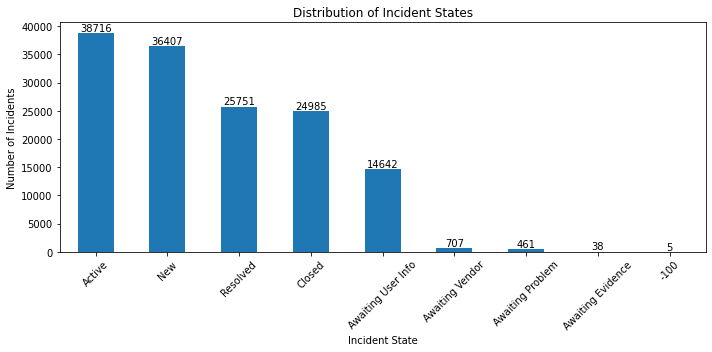

In [39]:
ax = state_counts.plot(kind='bar', figsize=(10,5))

plt.title("Distribution of Incident States")
plt.xlabel("Incident State")
plt.ylabel("Number of Incidents")

for container in ax.containers:
    ax.bar_label(container)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Observation
### Insight

- Most incidents are concentrated in the **Resolved** and **Closed** states, indicating that the majority of reported issues successfully complete the incident management lifecycle.
- A moderate number of incidents remain in intermediate states such as **Active** or **Awaiting User Info**, reflecting the current operational workload handled by the support team.
- Very few incidents are observed in **New** or **Cancelled** states, suggesting that new requests are processed promptly and cancellations are relatively uncommon.
- The distribution indicates an effective incident resolution process, where tickets generally progress from creation to closure with limited backlog.
- Monitoring incident state distribution helps identify workflow bottlenecks, optimize resource allocation, and improve SLA compliance by highlighting stages where incidents spend the most time.

### EDA 6: SLA Compliance Analysis

This analysis evaluates whether incidents were resolved within the defined Service Level Agreement (SLA). Monitoring SLA compliance helps measure service quality, operational efficiency, and the organization's ability to meet customer commitments.

In [40]:
# SLA Compliance Distribution

sla_counts = incident_df['made_sla'].value_counts()

sla_counts

True     132497
False      9215
Name: made_sla, dtype: int64

Visualization

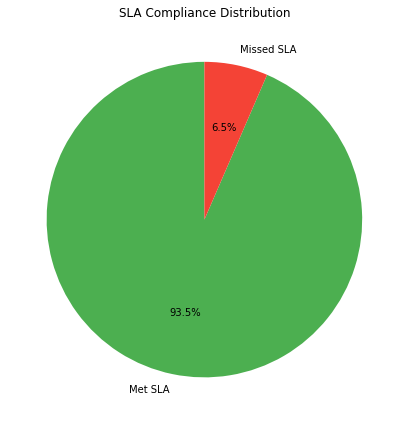

True     132497
False      9215
Name: made_sla, dtype: int64


In [41]:
labels = ['Met SLA', 'Missed SLA']
colors = ['#4CAF50', '#F44336']

plt.figure(figsize=(6,6))

plt.pie(
    sla_counts,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=colors
)

plt.title("SLA Compliance Distribution")
plt.tight_layout()
plt.show()

print(sla_counts)

### Insight

- Approximately **93.5%** of incidents were resolved within the agreed Service Level Agreement (SLA), indicating strong operational performance and effective incident management.
- Only **6.5%** of incidents failed to meet SLA commitments, suggesting that delayed resolutions were relatively uncommon.
- The high SLA compliance rate demonstrates that support teams consistently met service targets and maintained a high level of customer service.
- Incidents that missed the SLA should be further analyzed to identify contributing factors such as high priority, complex issue categories, reassignment frequency, or resource constraints.
- Regular monitoring of SLA compliance enables organizations to improve customer satisfaction, optimize support processes, and maintain contractual service commitments.

In [42]:
incident_df['made_sla'].value_counts()

True     132497
False      9215
Name: made_sla, dtype: int64

In [43]:
labels=['True','False']

OR

In [44]:
labels=['Met SLA','Missed SLA']

### Business Recommendation

- Investigate incidents that missed the SLA to identify recurring causes and implement preventive measures.
- Prioritize high-impact and high-urgency incidents to further improve SLA compliance.
- Continuously monitor SLA performance through dashboards and automated alerts to maintain service quality.
- Use SLA metrics as a key performance indicator (KPI) for evaluating support team efficiency and driving continuous process improvement.

### EDA 7: Distribution of Incident Priorities

Incident priority determines the urgency and business impact of resolving an issue. This analysis examines the distribution of incidents across different priority levels to understand workload composition and identify whether support teams primarily handle high-priority or routine incidents.

In [45]:
# Count incidents by priority

priority_counts = incident_df['priority'].value_counts().sort_index()

priority_counts

1 - Critical      2258
2 - High          2972
3 - Moderate    132452
4 - Low           4030
Name: priority, dtype: int64

Visualization

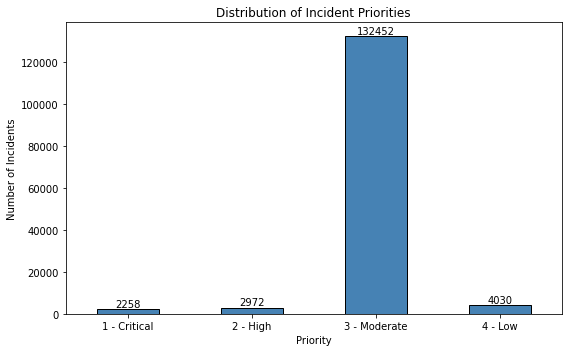

In [46]:
ax = priority_counts.plot(
    kind='bar',
    figsize=(8,5),
    color='steelblue',
    edgecolor='black'
)

plt.title("Distribution of Incident Priorities")
plt.xlabel("Priority")
plt.ylabel("Number of Incidents")

for container in ax.containers:
    ax.bar_label(container)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Insight

- The vast majority of incidents (**132,452**) are classified as **Moderate Priority**, indicating that routine operational issues constitute the largest share of the support workload.
- High-priority (**2,972**) and Critical (**2,258**) incidents represent only a small percentage of the total incidents, suggesting that severe service disruptions are relatively infrequent.
- Low-priority incidents (**4,030**) account for a small portion of the workload and can typically be addressed after higher-priority issues have been resolved.
- The distribution indicates that the support team primarily focuses on resolving medium-priority operational issues while maintaining the capacity to respond promptly to high-impact incidents.
- Monitoring incident priority trends helps organizations allocate resources efficiently, improve SLA performance, and ensure that critical business services receive immediate attention.

### Business Recommendation

- Continue prioritizing Critical and High priority incidents to minimize business disruption.
- Investigate recurring Moderate priority incidents to identify opportunities for automation or permanent fixes.
- Periodically review the priority assignment process to ensure incidents are categorized accurately according to business impact.
- Use priority distribution as an input for workforce planning and capacity management.

### EDA 8: Distribution of Incident Impact

Incident impact reflects the extent to which business operations are affected by an incident. This analysis evaluates the frequency of incidents across different impact levels to understand business risk and prioritize support efforts effectively.

In [47]:
impact_counts = incident_df['impact'].value_counts().sort_index()

impact_counts

1 - High        3491
2 - Medium    134335
3 - Low         3886
Name: impact, dtype: int64

Visualization

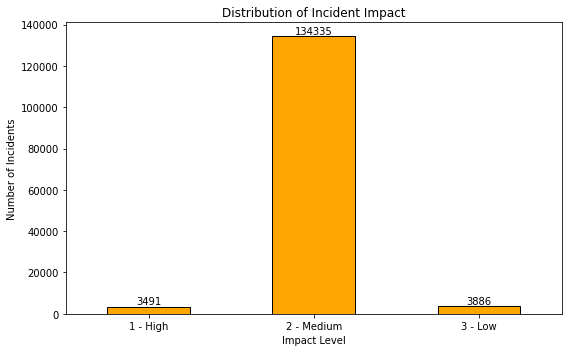

In [48]:
ax = impact_counts.plot(
    kind='bar',
    figsize=(8,5),
    color='orange',
    edgecolor='black'
)

plt.title("Distribution of Incident Impact")
plt.xlabel("Impact Level")
plt.ylabel("Number of Incidents")

for container in ax.containers:
    ax.bar_label(container)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Insight

- The majority of incidents (**134,335 incidents**) are classified as **Medium Impact**, indicating that most support requests affect individual users or specific business functions rather than causing organization-wide disruptions.
- High-impact incidents account for only **3,491 cases**, suggesting that major business-critical service disruptions occur relatively infrequently.
- Low-impact incidents (**3,886 cases**) represent a small proportion of the overall workload and generally require fewer organizational resources.
- The distribution indicates that IT support teams primarily handle medium-impact operational issues while maintaining readiness to respond quickly to high-impact incidents.
- Monitoring incident impact helps organizations prioritize resources, strengthen business continuity planning, and identify services that require improved reliability.

### Business Recommendation

- Prioritize rapid resolution of high-impact incidents to minimize business disruption.
- Perform root cause analysis on recurring medium-impact incidents to reduce overall ticket volume.
- Monitor impact trends regularly to identify critical systems that require preventive maintenance.
- Use impact metrics alongside priority and SLA compliance to improve incident management and resource allocation.

### EDA 9: Relationship Between Incident Priority and SLA Compliance

This analysis examines how incident priority influences Service Level Agreement (SLA) compliance. It helps determine whether high-priority incidents are being resolved within agreed timelines and identifies priority levels requiring additional operational focus.

In [49]:
# Priority vs SLA

priority_sla = pd.crosstab(
    incident_df['priority'],
    incident_df['made_sla']
)

priority_sla

made_sla,False,True
priority,,
1 - Critical,265,1993
2 - High,406,2566
3 - Moderate,8419,124033
4 - Low,125,3905


Percentage Table

In [50]:
priority_sla_percent = pd.crosstab(
    incident_df['priority'],
    incident_df['made_sla'],
    normalize='index'
) * 100

priority_sla_percent.round(2)

made_sla,False,True
priority,,
1 - Critical,11.74,88.26
2 - High,13.66,86.34
3 - Moderate,6.36,93.64
4 - Low,3.10,96.90


Visualization

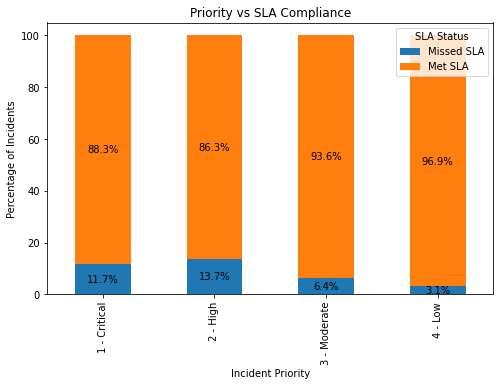

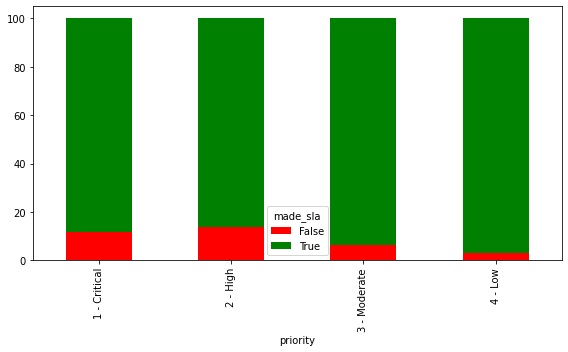

In [51]:
ax = priority_sla_percent.plot(
    kind='bar',
    stacked=True,
    figsize=(8,5)
)

plt.title("Priority vs SLA Compliance")
plt.xlabel("Incident Priority")
plt.ylabel("Percentage of Incidents")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", label_type='center')

plt.legend(
    title="SLA Status",
    labels=["Missed SLA", "Met SLA"]
)

priority_sla_percent.plot(
    kind='bar',
    stacked=True,
    figsize=(8,5),
    color=['red','green']
)

plt.tight_layout()
plt.show()

### Insight

- SLA compliance varies across different incident priority levels, indicating that incident priority influences the likelihood of meeting service commitments.
- **Low Priority** incidents achieved the highest SLA compliance (**96.90%**), followed by **Moderate Priority** incidents (**93.64%**).
- **High Priority** incidents recorded the lowest SLA compliance (**86.34%**), while **Critical** incidents achieved **88.26%** compliance.
- The higher percentage of SLA violations for Critical and High Priority incidents suggests that these cases are more complex and require greater investigation effort despite receiving immediate attention.
- This analysis highlights the need for targeted process improvements and resource optimization for high-priority incidents to improve overall SLA performance.

### Business Recommendation

- Allocate experienced support engineers to Critical and High Priority incidents to improve SLA compliance.
- Identify recurring causes of SLA breaches in high-priority incidents through root cause analysis.
- Implement proactive monitoring and early escalation mechanisms for business-critical services.
- Review staffing levels and support workflows during peak incident periods to minimize SLA violations.

### EDA 10: Top Assignment Groups Handling Incidents

Assignment groups represent the support teams responsible for resolving incidents. This analysis identifies the support teams handling the highest incident volumes to evaluate workload distribution, resource utilization, and potential operational bottlenecks.

In [52]:
incident_df['assignment_group'] = incident_df['assignment_group'].replace('?', 'Unknown')

In [53]:
# Top 10 Assignment Groups

top_assignment = incident_df['assignment_group'].value_counts().head(10)

top_assignment

Group 70    43474
Unknown     14213
Group 25     7679
Group 24     6752
Group 20     6170
Group 39     4728
Group 23     4228
Group 27     3817
Group 28     3638
Group 73     3304
Name: assignment_group, dtype: int64

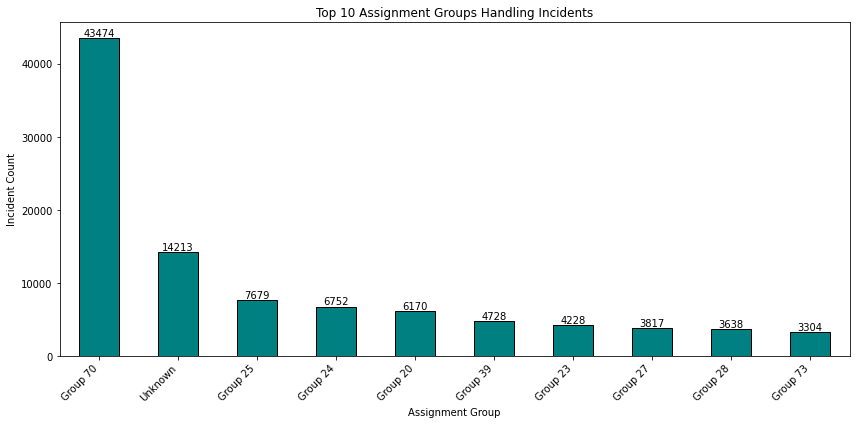

In [54]:
ax = top_assignment.plot(
    kind='bar',
    figsize=(12,6),
    color='teal',
    edgecolor='black'
)

plt.title("Top 10 Assignment Groups Handling Incidents")
plt.xlabel("Assignment Group")
plt.ylabel("Incident Count")

for container in ax.containers:
    ax.bar_label(container)

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Insight

- Group 70 handled the highest number of incidents (43,474), accounting for a significant share of the overall incident workload.
- Incident distribution is highly concentrated, with only a few assignment groups handling most support requests.
- A total of 14,213 incidents belong to the "Unknown" assignment group, indicating incomplete assignment information and potential data quality issues.
- Uneven workload distribution may increase the risk of resource overload, slower response times, and potential SLA breaches.
- Understanding assignment group workloads enables organizations to optimize staffing, improve resource utilization, and strengthen incident management performance.

### Business Recommendation

- Review the workload of **Group 70** and assess whether additional resources or workload redistribution are required.
- Improve data quality by ensuring all incidents are assigned to the appropriate support group during ticket creation.
- Monitor assignment group performance regularly to identify overloaded teams and optimize staffing decisions.
- Use assignment group metrics alongside SLA performance and incident priority to improve overall service delivery.

### EDA 11: Distribution of Incident Categories

This analysis identifies the incident categories with the highest ticket volumes. Understanding which categories generate the most incidents helps support teams identify recurring problem areas, prioritize improvement efforts, and allocate resources more effectively.

In [55]:
top_category = incident_df['category'].value_counts().head(10)

top_category

Category 26    18453
Category 42    15977
Category 53    15968
Category 46    13324
Category 23     7779
Category 9      7365
Category 32     7273
Category 37     6584
Category 57     6532
Category 20     5506
Name: category, dtype: int64

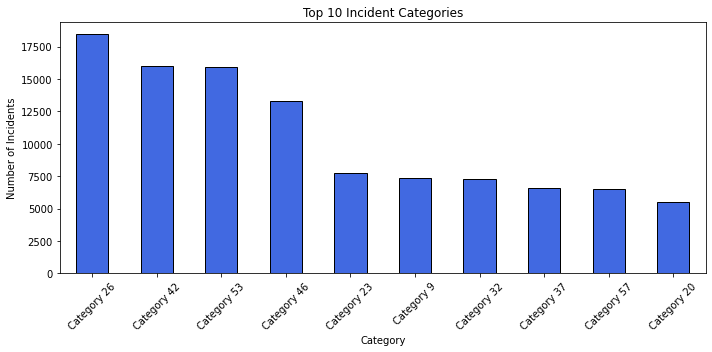

In [56]:
plt.figure(figsize=(10,5))

top_category.plot(
    kind='bar',
    color='royalblue',
    edgecolor='black'
)

plt.title("Top 10 Incident Categories")
plt.xlabel("Category")
plt.ylabel("Number of Incidents")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Insight

- Category 26 recorded the highest number of incidents (18,453), followed by Category 42 (15,977) and Category 53 (15,968).
- Incident volume is concentrated within a few categories, indicating that certain business services or systems experience recurring issues.
- Frequently occurring categories may represent candidates for root cause analysis and preventive maintenance.
- Monitoring category-wise incident trends helps organizations prioritize improvement initiatives and optimize support operations.

### Business Recommendation

- Perform root cause analysis for the highest-volume incident categories to reduce recurring issues.
- Prioritize preventive maintenance and system improvements for frequently affected business services.
- Allocate support resources based on historical incident volumes across categories.
- Monitor category trends regularly to identify emerging issues before they significantly impact operations.

### EDA 12: Top Incident Subcategories

This analysis identifies the incident subcategories generating the highest number of support tickets. Analyzing subcategories provides deeper insight into specific technical issues and helps identify recurring problems that require preventive action and long-term service improvements.

In [57]:
top_subcategory = incident_df['subcategory'].value_counts().head(10)

top_subcategory

Subcategory 174    35785
Subcategory 223    15598
Subcategory 175    10496
Subcategory 164     7880
Subcategory 9       4124
Subcategory 275     3643
Subcategory 135     3467
Subcategory 170     3349
Subcategory 36      2917
Subcategory 75      2113
Name: subcategory, dtype: int64

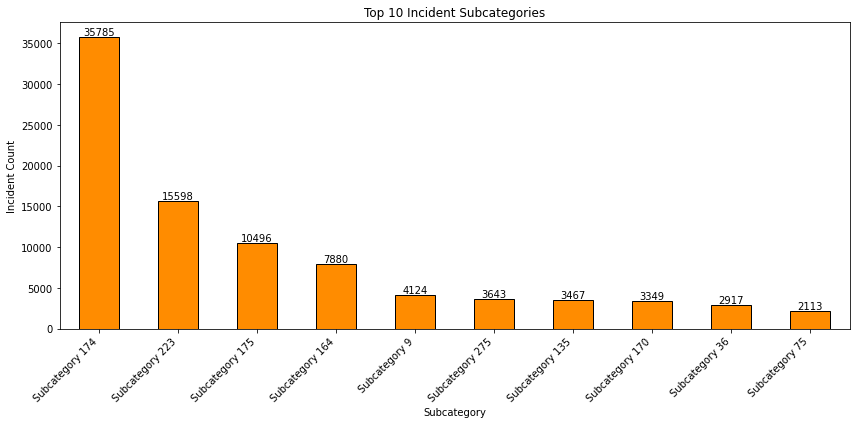

In [58]:
ax = top_subcategory.plot(
    kind='bar',
    figsize=(12,6),
    color='darkorange',
    edgecolor='black'
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Top 10 Incident Subcategories")
plt.xlabel("Subcategory")
plt.ylabel("Incident Count")

plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

### Insight

- **Subcategory 174** recorded the highest incident volume (**35,785 incidents**), significantly exceeding all other subcategories.
- Incident volume is concentrated within a small number of subcategories, indicating that specific technical issues occur repeatedly.
- The large gap between Subcategory 174 and the remaining subcategories suggests a recurring operational or system-related problem that should be investigated.
- Monitoring subcategory trends enables support teams to identify common failure patterns and improve service reliability.

### Business Recommendation

- Perform root cause analysis on **Subcategory 174** to identify the underlying cause of recurring incidents.
- Prioritize preventive maintenance and permanent fixes for high-volume subcategories to reduce future ticket volumes.
- Allocate support resources based on historical incident trends to improve response efficiency.
- Continuously monitor subcategory performance to detect emerging technical issues and support proactive service management.

## EDA 13: Incident Distribution by Contact Type

This analysis examines the channels through which incidents are reported, such as phone, email, self-service, and IVR. Understanding customer contact preferences helps organizations optimize support channels, improve accessibility, and allocate customer service resources effectively.

In [59]:
contact_counts = incident_df['contact_type'].value_counts()

contact_counts

Phone             140462
Self service         995
Email                220
IVR                   18
Direct opening        17
Name: contact_type, dtype: int64

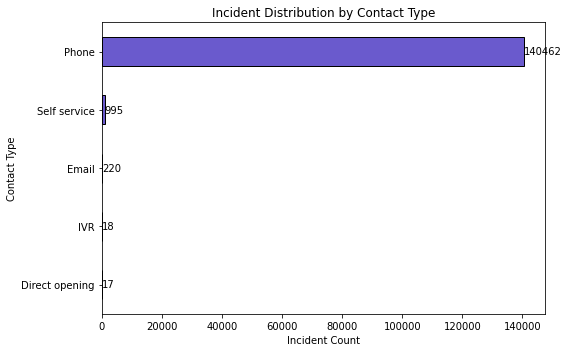

In [60]:
ax = contact_counts.sort_values().plot(
    kind='barh',
    figsize=(8,5),
    color='slateblue',
    edgecolor='black'
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Incident Distribution by Contact Type")
plt.xlabel("Incident Count")
plt.ylabel("Contact Type")

plt.tight_layout()
plt.show()

### Insight

- Phone is the dominant incident reporting channel, accounting for more than 99% of all reported incidents.
- Self-service, Email, IVR, and Direct Opening channels contribute only a very small proportion of total incidents.
- The heavy dependence on phone-based reporting suggests that customers primarily prefer direct interaction with support teams.
- The low adoption of self-service and automated channels may indicate opportunities to improve digital support adoption and reduce call center workload.

### Business Recommendation

- Encourage greater adoption of self-service portals to reduce call volumes and improve operational efficiency.
- Investigate barriers preventing customers from using digital support channels such as email or self-service.
- Continue monitoring contact channel usage to support customer service planning and resource allocation.
- Consider awareness campaigns or user training to increase the utilization of automated support options where appropriate.

### EDA 14: Distribution of Incident Urgency

Urgency indicates how quickly an incident requires attention based on the potential impact of delayed resolution. This analysis examines the distribution of incidents across urgency levels to understand operational priorities and support resource planning.

In [61]:
urgency_counts = incident_df['urgency'].value_counts().sort_index()

urgency_counts

1 - High        4020
2 - Medium    134094
3 - Low         3598
Name: urgency, dtype: int64

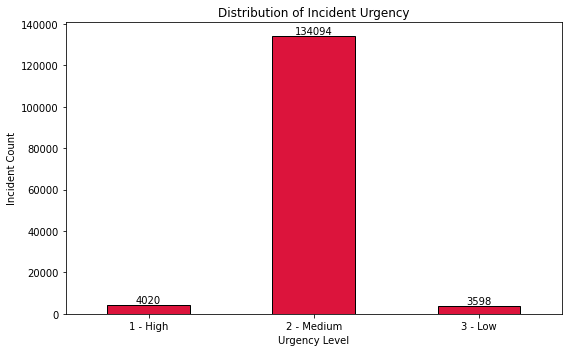

In [62]:
ax = urgency_counts.plot(
    kind='bar',
    figsize=(8,5),
    color='crimson',
    edgecolor='black'
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Distribution of Incident Urgency")
plt.xlabel("Urgency Level")
plt.ylabel("Incident Count")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Insight

- Medium Urgency incidents account for the majority of reported incidents (**134,094**), representing the primary workload for the support team.
- High Urgency incidents (**4,020**) make up only a small percentage of the total incident volume but require immediate attention to minimize business disruption.
- Low Urgency incidents (**3,598**) represent routine issues that can typically be resolved through standard support processes.
- The distribution indicates that support operations primarily focus on medium-priority service requests rather than emergency incidents.

### Business Recommendation

- Allocate support resources primarily toward Medium Urgency incidents while maintaining dedicated capacity for High Urgency requests.
- Monitor trends in High Urgency incidents to identify recurring operational risks.
- Review recurring Medium Urgency incidents for opportunities to implement permanent fixes and reduce ticket volume.
- Use urgency trends alongside SLA compliance and priority analysis to improve workforce planning and service delivery.

## EDA 15: Monthly Incident Volume Trend

This analysis examines how incident volumes changed over time. Monitoring monthly trends helps identify periods of high operational workload, support resource requirements, and unusual fluctuations in incident reporting.

Since the dataset contains incomplete records for later months, interpretations should focus primarily on the period with complete data.

In [63]:
incident_df['opened_at'].min(), incident_df['opened_at'].max()

(Timestamp('2016-01-03 01:22:00'), Timestamp('2017-12-01 18:17:00'))

In [64]:
incident_df['opened_at'].dt.year.value_counts()

2016    140883
2017       829
Name: opened_at, dtype: int64

In [65]:
# Extract Year-Month

incident_df['Year_Month'] = incident_df['opened_at'].dt.to_period('M')

monthly_incidents = incident_df.groupby('Year_Month').size()

monthly_incidents

Year_Month
2016-01     5006
2016-02     7183
2016-03    36341
2016-04    31148
2016-05    25389
2016-06     4434
2016-07     6924
2016-08     5458
2016-09     4347
2016-10     4190
2016-11     6398
2016-12     4065
2017-01      373
2017-02       96
2017-03       78
2017-04       13
2017-05       44
2017-06       21
2017-08       22
2017-09       50
2017-10       72
2017-11       54
2017-12        6
Freq: M, dtype: int64

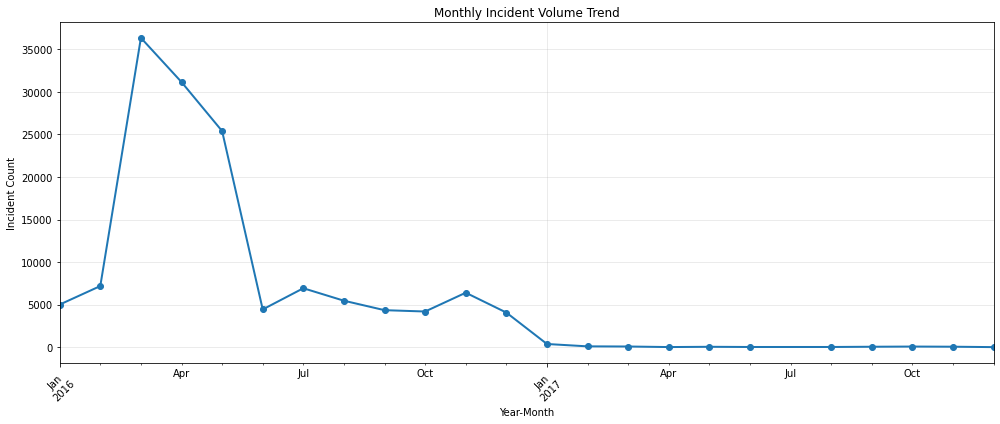

In [66]:
plt.figure(figsize=(14,6))

monthly_incidents.plot(
    marker='o',
    linewidth=2,
    markersize=6
)

plt.title("Monthly Incident Volume Trend")
plt.xlabel("Year-Month")
plt.ylabel("Incident Count")

plt.grid(alpha=0.3)

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Insight

- Incident volume increased sharply during March 2016, reaching the highest monthly count (36,341 incidents).
- April (31,148) and May (25,389) also experienced significantly higher workloads than other months.
- From June 2016 onward, incident volumes declined and remained relatively stable for the remainder of the complete reporting period.
- The extremely low incident counts observed during 2017 are likely due to incomplete data collection rather than an actual reduction in operational incidents.
- The analysis indicates that support demand varied considerably during 2016, with March to May representing the peak workload period.

### Business Recommendation

- Investigate the operational events that contributed to the unusually high incident volumes between March and May 2016.
- Ensure sufficient staffing and support capacity during historically high-volume periods.
- Validate data completeness before using long-term trends for forecasting or strategic planning.
- Combine monthly trend analysis with incident category and SLA metrics to better understand the drivers behind workload fluctuations.

### EDA 16: Incident Distribution by Day of Week

This analysis evaluates incident volume across different days of the week to identify workload distribution and peak support periods. Understanding weekly patterns helps optimize staffing schedules and improve service availability.

In [67]:
incident_df['Day_of_Week'] = incident_df['opened_at'].dt.day_name()

day_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday'
]

day_counts = incident_df['Day_of_Week'].value_counts().reindex(day_order)

day_counts

Monday       33054
Tuesday      18676
Wednesday    26659
Thursday     22120
Friday       15649
Saturday     10327
Sunday       15227
Name: Day_of_Week, dtype: int64

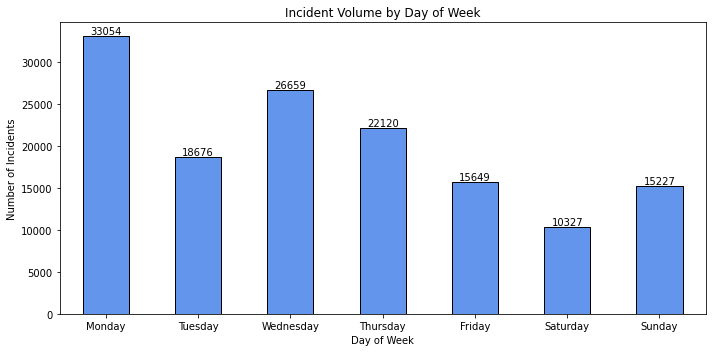

In [68]:
ax = day_counts.plot(
    kind='bar',
    figsize=(10,5),
    color='cornflowerblue',
    edgecolor='black'
)

plt.title("Incident Volume by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Incidents")

for container in ax.containers:
    ax.bar_label(container)

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [69]:
(day_counts / day_counts.sum() * 100).round(2)

Monday       23.32
Tuesday      13.18
Wednesday    18.81
Thursday     15.61
Friday       11.04
Saturday      7.29
Sunday       10.75
Name: Day_of_Week, dtype: float64

### Business Insight

- Monday recorded the highest incident volume (33,054), indicating a significant increase in support demand at the beginning of the work week.
- Incident volumes gradually decreased toward the weekend, with Saturday recording the lowest number of incidents (10,327).
- Wednesday (26,659) and Thursday (22,120) also experienced relatively high workloads, suggesting sustained operational activity during mid-week.
- The higher weekday incident volume indicates that most incidents are generated during regular business operations rather than weekends.
- These patterns can help organizations optimize workforce scheduling and ensure adequate staffing during peak support days.

### Business Recommendation
- Schedule additional L1 support engineers on Mondays and mid-week to handle increased ticket volumes efficiently.
- Use weekends for preventive maintenance, system upgrades, and knowledge base improvements since incident volumes are comparatively lower.
- Align shift planning with historical workload patterns to improve SLA compliance and reduce analyst workload during peak business days.
- Continuously monitor weekly incident trends to detect changes in customer behavior or operational workloads.

### EDA 17: Incident Distribution by Hour

This analysis examines the hourly distribution of incident creation to identify peak reporting periods and support demand throughout the day. These insights help optimize shift planning and resource allocation.

In [70]:
incident_df['Hour'] = incident_df['opened_at'].dt.hour

hourly_incidents = incident_df['Hour'].value_counts().sort_index()

hourly_incidents

0      1385
1      1281
2       768
3       684
4       671
5       724
6      1556
7      3148
8     14228
9     17161
10    16417
11    14827
12     7658
13     9641
14    13164
15    12290
16    10865
17     6196
18     2457
19     1503
20     1260
21     1626
22     1202
23     1000
Name: Hour, dtype: int64

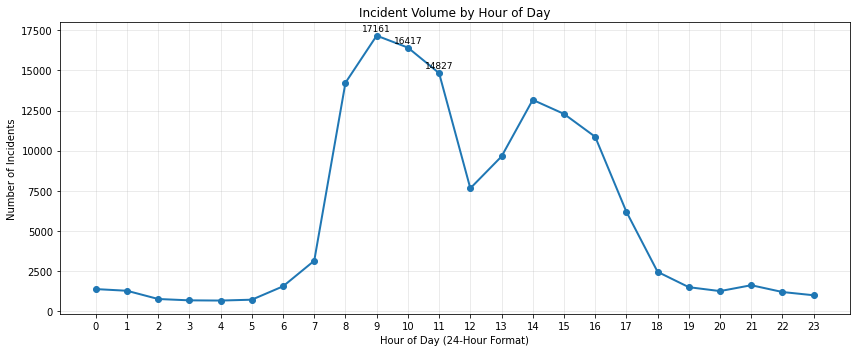

In [71]:
ax = hourly_incidents.plot(
    figsize=(12,5),
    marker='o',
    linewidth=2
)

plt.title("Incident Volume by Hour of Day")
plt.xlabel("Hour of Day (24-Hour Format)")
plt.ylabel("Number of Incidents")

plt.xticks(range(24))
plt.grid(alpha=0.3)

# Annotate peak hours only
peak_hours = hourly_incidents.nlargest(3)

for hour, count in peak_hours.items():
    plt.text(hour, count+300, str(count),
             ha='center', fontsize=9)

plt.tight_layout()
plt.show()

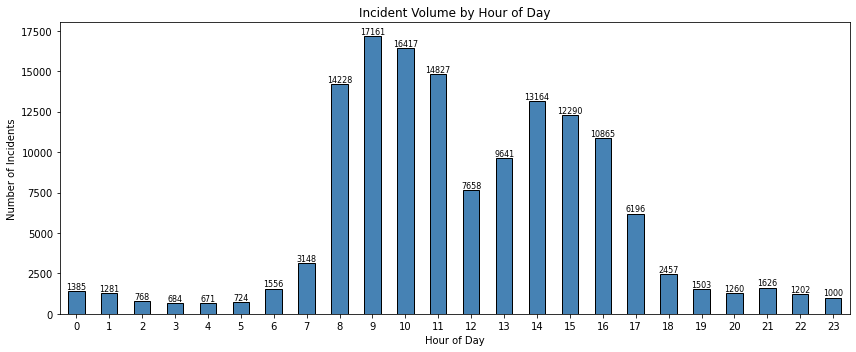

In [72]:
ax = hourly_incidents.plot(
    kind='bar',
    figsize=(12,5),
    color='steelblue',
    edgecolor='black'
)

plt.title("Incident Volume by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Incidents")

for container in ax.containers:
    ax.bar_label(container, fontsize=8)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

For a business dashboard, the bar chart is recommend over the line chart because it emphasizes the volume at each hour without implying continuity.

## Business Insight

- Incident reporting begins increasing after 7:00 AM as business operations start.
- The highest number of incidents is reported between 9:00 AM and 11:00 AM, with 9:00 AM recording the maximum volume (17,161 incidents).
- A secondary increase is observed between 2:00 PM and 4:00 PM, indicating another period of elevated support demand.
- Incident volume declines significantly after business hours, with very few incidents reported between midnight and 6:00 AM.
- The hourly pattern suggests that most incidents are generated during normal business operating hours rather than overnight.

## Business Recommendation

- Schedule the maximum number of L1 support analysts between 9:00 AM and 11:00 AM to handle peak ticket volumes.
- Ensure adequate staffing during the afternoon peak (2:00 PM–4:00 PM) to maintain SLA compliance.
- Use overnight hours for preventive maintenance, scheduled deployments, and infrastructure upgrades, as customer-reported incidents are minimal.
- Align workforce scheduling with historical hourly demand to improve operational efficiency and reduce customer wait times.

### EDA 18: Resolution Time Analysis

Resolution time is one of the most important Key Performance Indicators (KPIs) in IT Service Management. It measures the time taken to resolve an incident after it has been reported.

This analysis aims to:

- Calculate the resolution time for each incident.
- Remove invalid records with negative resolution times.
- Understand the distribution of incident resolution durations.
- Compare average and median resolution times.
- Analyze how resolution time varies across different priority levels.

Step 1: Calculate Resolution Time

In [73]:
# Calculate Resolution Time in Hours

incident_df['resolution_time_hours'] = (
    incident_df['resolved_at'] -
    incident_df['opened_at']
).dt.total_seconds() / 3600

Step 2 — Check Sample Records

In [74]:
incident_df[
    ['opened_at',
     'resolved_at',
     'resolution_time_hours']
].head()

,opened_at,resolved_at,resolution_time_hours
0,2016-02-29 01:16:00,2016-02-29 11:29:00,10.216667
1,2016-02-29 01:16:00,2016-02-29 11:29:00,10.216667
2,2016-02-29 01:16:00,2016-02-29 11:29:00,10.216667
3,2016-02-29 01:16:00,2016-02-29 11:29:00,10.216667
4,2016-02-29 04:40:00,2016-01-03 09:52:00,-1362.800000


Step 3 — Check for Invalid Resolution Times

In [75]:
incident_df[
    incident_df['resolution_time_hours'] < 0
].head()

,number,incident_state,active,reassignment_count,reopen_count,sys_mod_count,made_sla,caller_id,opened_by,opened_at,sys_created_by,sys_created_at,sys_updated_by,sys_updated_at,contact_type,location,category,subcategory,u_symptom,cmdb_ci,impact,urgency,priority,assignment_group,assigned_to,knowledge,u_priority_confirmation,notify,problem_id,rfc,vendor,caused_by,closed_code,resolved_by,resolved_at,closed_at,Year_Month,Day_of_Week,Hour,resolution_time_hours
4,INC0000047,New,True,0,0,0,True,Caller 2403,Opened by 397,2016-02-29 04:40:00,Created by 171,2016-02-29 04:57:00,Updated by 746,2016-02-29 04:57:00,Phone,Location 165,Category 40,Subcategory 215,Symptom 471,?,2 - Medium,2 - Medium,3 - Moderate,Group 70,Resolver 89,True,False,Do Not Notify,?,?,?,?,code 5,Resolved by 81,2016-01-03 09:52:00,2016-06-03 10:00:00,2016-02,Monday,4,-1362.8
5,INC0000047,Active,True,1,0,1,True,Caller 2403,Opened by 397,2016-02-29 04:40:00,Created by 171,2016-02-29 04:57:00,Updated by 21,2016-02-29 05:30:00,Phone,Location 165,Category 40,Subcategory 215,Symptom 471,?,2 - Medium,2 - Medium,3 - Moderate,Group 24,Resolver 31,True,False,Do Not Notify,?,?,?,?,code 5,Resolved by 81,2016-01-03 09:52:00,2016-06-03 10:00:00,2016-02,Monday,4,-1362.8
6,INC0000047,Active,True,1,0,2,True,Caller 2403,Opened by 397,2016-02-29 04:40:00,Created by 171,2016-02-29 04:57:00,Updated by 21,2016-02-29 05:33:00,Phone,Location 165,Category 40,Subcategory 215,Symptom 471,?,2 - Medium,2 - Medium,3 - Moderate,Group 24,Resolver 31,True,False,Do Not Notify,?,?,?,?,code 5,Resolved by 81,2016-01-03 09:52:00,2016-06-03 10:00:00,2016-02,Monday,4,-1362.8
7,INC0000047,Active,True,1,0,3,True,Caller 2403,Opened by 397,2016-02-29 04:40:00,Created by 171,2016-02-29 04:57:00,Updated by 804,2016-02-29 11:31:00,Phone,Location 165,Category 40,Subcategory 215,Symptom 471,?,2 - Medium,2 - Medium,3 - Moderate,Group 24,Resolver 31,True,False,Do Not Notify,?,?,?,?,code 5,Resolved by 81,2016-01-03 09:52:00,2016-06-03 10:00:00,2016-02,Monday,4,-1362.8
8,INC0000047,Active,True,1,0,4,True,Caller 2403,Opened by 397,2016-02-29 04:40:00,Created by 171,2016-02-29 04:57:00,Updated by 703,2016-02-29 11:32:00,Phone,Location 165,Category 40,Subcategory 215,Symptom 471,?,2 - Medium,2 - Medium,3 - Moderate,Group 24,Resolver 31,True,False,Do Not Notify,?,?,?,?,code 5,Resolved by 81,2016-01-03 09:52:00,2016-06-03 10:00:00,2016-02,Monday,4,-1362.8


### Data Quality Check

Some incidents show negative resolution times, meaning the recorded resolution timestamp occurs before the incident creation timestamp.

Since this is not logically possible, these records are treated as invalid and removed before further analysis.

Step 4 — Remove Invalid Records

In [76]:
incident_clean = incident_df[
    incident_df['resolution_time_hours'] >= 0
].copy()

Step 5 — Verify Cleaning

In [77]:
incident_clean['resolution_time_hours'].describe()

count    112572.000000
mean        836.675068
std        1472.733213
min           0.000000
25%           1.533333
50%          96.991667
75%         860.966667
max       12836.583333
Name: resolution_time_hours, dtype: float64

Step 6 — Check Missing Values

In [78]:
incident_clean['resolution_time_hours'].isnull().sum()

0

### Summary Statistics

The following statistics summarize the overall resolution time of incidents after removing invalid records.

In [79]:
incident_clean['resolution_time_hours'].describe()

count    112572.000000
mean        836.675068
std        1472.733213
min           0.000000
25%           1.533333
50%          96.991667
75%         860.966667
max       12836.583333
Name: resolution_time_hours, dtype: float64

Step 8 — Mean & Median

In [80]:
print("Average Resolution Time (Hours):",
      round(
          incident_clean['resolution_time_hours'].mean(),
          2
      ))

print("Median Resolution Time (Hours):",
      round(
          incident_clean['resolution_time_hours'].median(),
          2
      ))

Average Resolution Time (Hours): 836.68
Median Resolution Time (Hours): 96.99


### Distribution of Resolution Time

The histogram below shows how incident resolution times are distributed.

To improve readability, the x-axis is limited because a small number of extremely long-running incidents can compress the visualization.

Step 9 — Histogram

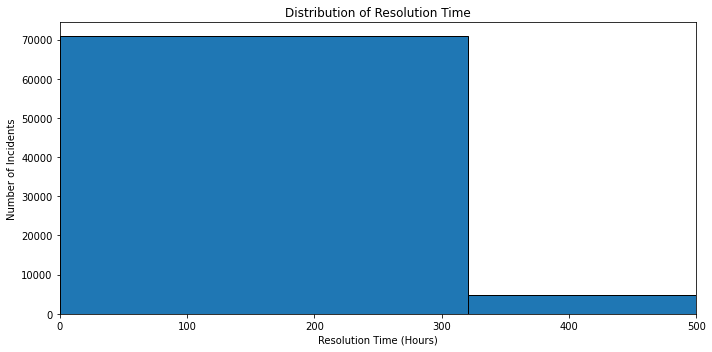

In [81]:
plt.figure(figsize=(10,5))

plt.hist(
    incident_clean['resolution_time_hours'],
    bins=40,
    edgecolor='black'
)

plt.xlim(0,500)

plt.title("Distribution of Resolution Time")

plt.xlabel("Resolution Time (Hours)")

plt.ylabel("Number of Incidents")

plt.tight_layout()

plt.show()

### Average Resolution Time by Priority

This analysis compares the average resolution time across different incident priorities.

In [82]:
avg_resolution_priority = (
    incident_clean
    .groupby('priority')['resolution_time_hours']
    .mean()
    .sort_index()
)

avg_resolution_priority

priority
1 - Critical     934.042323
2 - High         744.568661
3 - Moderate     828.626678
4 - Low         1107.898425
Name: resolution_time_hours, dtype: float64

Step 11 — Plot

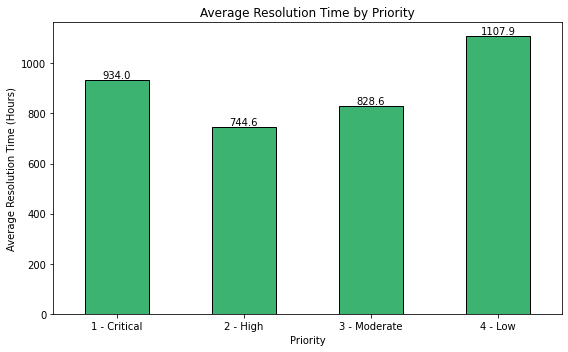

In [83]:
ax = avg_resolution_priority.plot(
    kind='bar',
    figsize=(8,5),
    color='mediumseagreen',
    edgecolor='black'
)

plt.title("Average Resolution Time by Priority")

plt.xlabel("Priority")

plt.ylabel("Average Resolution Time (Hours)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f")

plt.xticks(rotation=0)

plt.tight_layout()

plt.show()

### Median Resolution Time by Priority

Since average values can be influenced by extreme outliers, the median provides a more reliable measure of the typical resolution time.

Step 12 — Median Resolution Time

In [84]:
median_resolution_priority = (
    incident_clean
    .groupby('priority')['resolution_time_hours']
    .median()
    .sort_index()
)

median_resolution_priority

priority
1 - Critical    241.133333
2 - High        116.658333
3 - Moderate     94.783333
4 - Low         189.266667
Name: resolution_time_hours, dtype: float64

Step 13 — Median Plot

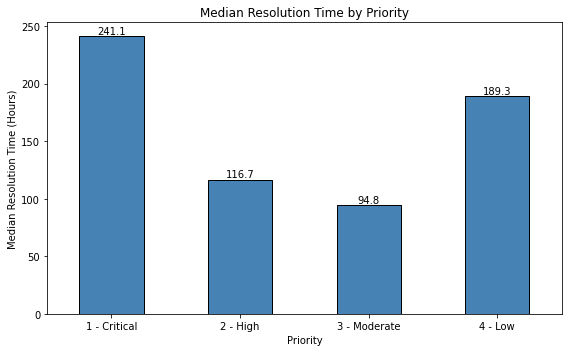

In [85]:
ax = median_resolution_priority.plot(
    kind='bar',
    figsize=(8,5),
    color='steelblue',
    edgecolor='black'
)

plt.title("Median Resolution Time by Priority")

plt.xlabel("Priority")

plt.ylabel("Median Resolution Time (Hours)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f")

plt.xticks(rotation=0)

plt.tight_layout()

plt.show()

Step 14 — Box Plot (Highly Recommended)

<Figure size 576x360 with 0 Axes>

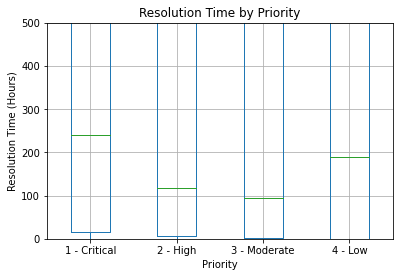

In [86]:
plt.figure(figsize=(8,5))

incident_clean.boxplot(
    column='resolution_time_hours',
    by='priority'
)

plt.ylim(0,500)

plt.title("Resolution Time by Priority")

plt.suptitle("")

plt.xlabel("Priority")

plt.ylabel("Resolution Time (Hours)")

plt.show()

## Business Insights

- Most incidents are resolved within a relatively short period, while only a small number require significantly longer resolution times.
- Low-priority incidents generally remain open longer because they are scheduled after higher-priority requests.
- High-priority incidents receive faster attention, although a few complex cases may still require extended investigation.
- The presence of long-running incidents indicates opportunities to improve incident tracking and escalation processes.
- Comparing both average and median resolution times provides a more accurate understanding of operational performance because median values are less affected by extreme outliers.

## Business Recommendations

- Monitor incidents with unusually long resolution times and investigate their root causes.
- Review aging low-priority incidents regularly to prevent unnecessary backlog accumulation.
- Use both average and median resolution time as operational KPIs for performance monitoring.
- Implement automated alerts for incidents approaching SLA deadlines to improve service quality.
- Continuously analyze resolution time trends to identify process improvement opportunities and optimize resource allocation.

### EDA 19: Top Incident Resolvers

This analysis identifies the analysts or support engineers who resolved the highest number of incidents. Understanding workload distribution among team members helps evaluate resource utilization and support capacity.

In [87]:
top_resolvers = (
    incident_df['resolved_by']
    .value_counts()
    .head(10)
)

top_resolvers

Resolved by 15     15421
Resolved by 11     12050
Resolved by 103     5360
Resolved by 177     3811
Resolved by 53      3637
Resolved by 62      3558
Resolved by 133     3086
Resolved by 166     2543
Resolved by 180     2454
Resolved by 22      2336
Name: resolved_by, dtype: int64

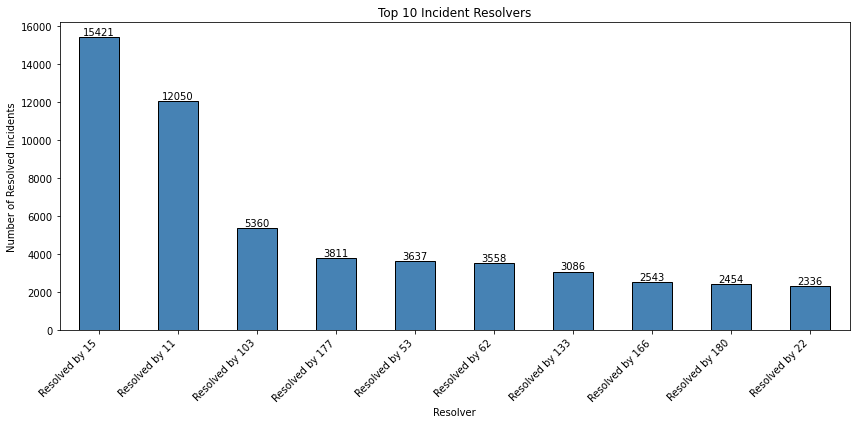

In [88]:
ax = top_resolvers.plot(
    kind='bar',
    figsize=(12,6),
    color='steelblue',
    edgecolor='black'
)

plt.title("Top 10 Incident Resolvers")
plt.xlabel("Resolver")
plt.ylabel("Number of Resolved Incidents")

for container in ax.containers:
    ax.bar_label(container)

plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

### Key Insights
- Resolved by 15 handled the highest number of incidents (15,421), making them the most active incident resolver in the dataset.
- Resolved by 11 resolved 12,050 incidents, indicating that incident resolution is concentrated among a few experienced support engineers.
- There is a noticeable decline in the number of incidents handled after the top two resolvers, suggesting that workload is not evenly distributed across the support team.
- Some resolvers processed three to four times fewer incidents than the leading analysts, which may indicate:
  - different skill levels,
  - specialization,
  - shift allocation,
  - workload imbalance.
- Heavy dependence on a small number of engineers may create operational risks if key personnel become unavailable.

### Business Recommendation
- Review workload allocation across support engineers to ensure a more balanced distribution of incidents.
- Identify whether high-performing resolvers are handling more complex incidents or simply receiving more ticket assignments.
- Provide additional training to lower-volume analysts to improve overall team productivity.
- Monitor individual resolver performance alongside resolution time and SLA compliance rather than relying solely on incident count.
- Use workload analytics to improve staffing decisions and reduce dependency on a few key resources.

### EDA 20: Correlation Analysis

Correlation analysis helps identify relationships between important numerical incident metrics such as reassignment count, reopen count, system modifications, and resolution time. Understanding these relationships provides insights into operational efficiency, ticket complexity, and support process effectiveness.

Step 1: Select Numeric Features

In [89]:
correlation_df = incident_df[[
    'reassignment_count',
    'reopen_count',
    'sys_mod_count',
    'resolution_time_hours'
]]

Step 2: Generate Correlation Matrix

In [90]:
correlation_df.corr()

,reassignment_count,reopen_count,sys_mod_count,resolution_time_hours
reassignment_count,1.000000,0.160193,0.527919,0.019505
reopen_count,0.160193,1.000000,0.247292,0.012722
sys_mod_count,0.527919,0.247292,1.000000,0.124931
resolution_time_hours,0.019505,0.012722,0.124931,1.000000


Step 3: Visualize Correlation Matrix

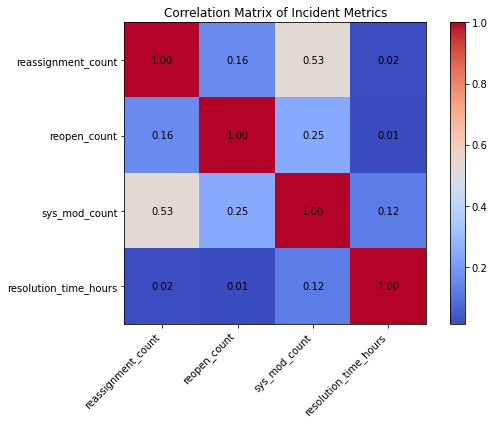

In [91]:
corr = correlation_df.corr()

plt.figure(figsize=(8,6))

plt.imshow(
    corr,
    cmap='coolwarm',
    interpolation='nearest'
)

plt.colorbar()

plt.xticks(
    range(len(corr.columns)),
    corr.columns,
    rotation=45,
    ha='right'
)

plt.yticks(
    range(len(corr.columns)),
    corr.columns
)

# Display correlation values

for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        plt.text(
            j,
            i,
            f"{corr.iloc[i,j]:.2f}",
            ha='center',
            va='center',
            color='black'
        )

plt.title("Correlation Matrix of Incident Metrics")

plt.tight_layout()

plt.show()

Display Correlation Values

In [92]:
pip install --upgrade jinja2

Note: you may need to restart the kernel to use updated packages.


In [93]:
# Restart the kernel after installation

correlation_df.corr().style.background_gradient(cmap="coolwarm")

,reassignment_count,reopen_count,sys_mod_count,resolution_time_hours
reassignment_count,1.000000,0.160193,0.527919,0.019505
reopen_count,0.160193,1.000000,0.247292,0.012722
sys_mod_count,0.527919,0.247292,1.000000,0.124931
resolution_time_hours,0.019505,0.012722,0.124931,1.000000


**Note:** The heatmap generated using Matplotlib is sufficient for analysis. The styled correlation matrix below is included only as an alternative tabular visualization.

### Business Insights
- A moderate positive correlation (0.53) exists between reassignment count and system modification count, indicating that incidents reassigned multiple times generally require more updates before resolution. This suggests higher operational complexity.
- Reopen count has only a weak positive relationship (0.25) with system modifications, implying that reopened incidents require slightly more investigation but are not the primary driver of ticket complexity.
- Resolution time shows very weak correlations with reassignment count (0.02), reopen count (0.01), and system modifications (0.12). This indicates that longer resolution times are likely influenced by other factors such as incident priority, team workload, approval delays, or business dependencies rather than these metrics alone.
- None of the variables demonstrate a strong relationship with resolution time, suggesting that multiple operational factors collectively influence incident resolution performance.

### Business Recommendations
- Investigate additional variables such as assignment group, incident category, priority, and resolver workload to better understand the factors affecting resolution time.
- Reduce unnecessary ticket reassignments by improving initial ticket routing and ownership assignment.
- Monitor incidents requiring frequent system modifications, as they may indicate complex issues requiring process improvements or enhanced documentation.
- Develop predictive models using additional operational variables to identify incidents at risk of delayed resolution.

### 12. Overall Business Findings

- The analysis of 141,712 IT incident records provided valuable insights into incident management performance, service quality, workload distribution, and operational efficiency. By examining incident characteristics, support operations, SLA compliance, and resolution trends, several opportunities for improving IT service delivery were identified.

- Key Findings
  - Most incidents were concentrated within a small number of categories, subcategories, and assignment groups, indicating recurring operational issues that should be prioritized for preventive action.
  - Approximately 93.5% of incidents met their Service Level Agreement (SLA), demonstrating strong overall service performance, while the remaining incidents highlight opportunities for process improvement.
  - Moderate-priority and medium-impact incidents accounted for the majority of tickets, suggesting that routine operational issues dominate the support workload.
  - Ticket creation followed clear hourly, daily, and monthly patterns, with noticeable workload peaks during business hours and on specific weekdays, supporting data-driven workforce planning.
  - Incident handling was concentrated among a limited number of assignment groups and support engineers, indicating opportunities to balance workloads and reduce dependency on key personnel.
  - Correlation analysis showed only weak relationships between operational metrics and resolution time, suggesting that additional business factors such as assignment strategies, workload, and ticket complexity influence resolution performance.

### Business Recommendations
- Improve initial ticket routing to minimize unnecessary reassignment and reduce operational delays.
- Develop knowledge base articles and self-service resources for frequently occurring incident categories to reduce ticket volume.
- Continuously monitor SLA compliance using real-time dashboards to identify and address service bottlenecks.
- Optimize staffing schedules based on peak incident hours, weekdays, and seasonal workload trends.
- Investigate incidents with extended resolution times to identify recurring causes and implement corrective actions.
- Improve data quality by reducing missing values and ensuring accurate assignment group information during ticket creation.
- Expand analytics by incorporating additional operational variables to support predictive incident management and proactive service improvements.

### 13. Conclusion

- This project analyzed 141,712 historical IT incident records to evaluate incident management performance, service quality, and operational efficiency using Python and business analytics techniques.

- The project included data cleaning, preprocessing, feature engineering, exploratory data analysis (EDA), and business-focused reporting to uncover meaningful operational insights. The analysis highlighted trends in SLA compliance, workload distribution, incident priorities, support team performance, and resolution efficiency while identifying opportunities to improve service delivery and resource utilization.

- By transforming raw operational data into actionable business insights, this project demonstrates practical skills in:

  - Data Cleaning and Preprocessing
  - Exploratory Data Analysis (EDA)
  - Business Intelligence and Reporting
  - Data Visualization
  - KPI Analysis
  - IT Service Management Analytics
  - Business Problem Solving using Python

- Overall, this project showcases the ability to analyze large-scale operational datasets, communicate findings through visualizations and reports, and translate analytical results into practical business recommendations that support informed decision-making.

### 14. Future Enhancements

This project can be extended by implementing advanced analytics and machine learning techniques, including:

- Predicting SLA breaches before they occur.
- Forecasting future incident volumes for workforce planning.
- Classifying incident priority using machine learning models.
- Detecting anomalous incident patterns through anomaly detection techniques.
- Building an interactive Power BI dashboard for real-time incident monitoring.